In [1]:
import nugget
import importlib

In [37]:
device='cuda:0'
geometry = nugget.geometries.DynamicString.DynamicString(
                device=device,
                hex_type='hexagonal',
                n_cjbs=20,  # Number of CJBs
                # random_xy=True,
                domain_size=1600,  # Size of detector domain
                dim=3,  # 3D geometry
                n_strings=70,  # Initial number of detector strings
                points_per_string=20,  # Number of PMTs/sensors per string
                # custom_string_spacing=50  # Custom spacing between strings
                custom_z_spacing=50,
                random_assignment_logits=True,
                assignment_logits_init=1,
                assignment_logits_std=2,
                assignment_activation='softmax',
                cjb_weight_gate='probability',  
            ) # Initialize the dynamic string geometry object

visualizer = nugget.utils.vis_tools.Visualizer(
    device=device,
    dim=3, 
    domain_size=1400,
    # gif_temp_dir='./gif_temp_3',  # Directory for storing animation frames
    ) # Initialize the visualizer for live visualization of the geometry and optimization process

In [38]:
# using here the hybrid optimizer which allows for the use of both JAX and PyTorch for optimization
optimizer = nugget.utils.basic_optimizer.Optimizer(
    device=geometry.device, 
    geometry=geometry,
    visualizer=visualizer,
    # conflict_free=False,  # Single-objective optimization (vs multi-objective)
    use_alm=True,  # Use Augmented Lagrangian Method for constraints
    sigmoid_losses=True,
)
# initialize optimizer and create the initial geometry, specifying which parameters to optimize and their learning rates
optimizer.init_geometry(
    # opt_list=[('string_weights', 0.5)],  # Learning rate for string weights (without sigmoid applied)
    opt_list=[('cjb_xy', 10), ('assignment_logits', 0.1)],  # Learning rates for string xy positions
)

Optimizing cjb_xy with torch.Size([20, 2]) shape
Optimizing assignment_logits with torch.Size([70, 20]) shape


In [39]:
importlib.reload(nugget.losses.geometry_penalties)
importlib.reload(nugget.losses.cost_loss)

# Local String Repulsion: Prevents strings from getting too close to each other
local_string_repulsion_penalty = nugget.losses.geometry_penalties.LocalStringRepulsionPenalty(
    device=geometry.device
)

cost_loss = nugget.losses.cost_loss.CostLoss(
    device=geometry.device,
    C_cable=2.0,  # Cost per unit length of cable
    C_cjb=150e1,  # Cost per CJB
    C_connection=20e1,  # Cost per connection
)

cjb_capacity_penalty = nugget.losses.geometry_penalties.CJBCapacityPenalty(
    device=geometry.device,
    cjb_capacity=8,  # Maximum number of strings per CJB
)

string_connection_penalty = nugget.losses.geometry_penalties.StringConnectionPenalty(
    device=geometry.device,
)

cjb_connection_binarization_penalty = nugget.losses.geometry_penalties.CJBConnectionBinarizationPenalty(
    device=geometry.device,
)
# # String Boundary Penalty: Keeps strings within the detector domain
# string_boundary_penalty = nugget.losses.geometry_penalties.StringBoundaryPenaltyCircle(
#     device=geometry.device,
# )

# # String Number Penalty: Penalizes having too many active strings
# string_number_penalty = nugget.losses.geometry_penalties.StringNumberPenalty(
#     device=geometry.device
# )

# # Weight Binarization: Encourages string weights to be either 0 or 1
# weighted_binarization_penalty = nugget.losses.geometry_penalties.WeightBinarizationPenalty(
#     device=geometry.device
# )


# ROV Penalty: Accounts for physical constraints from Remotely Operated Vehicle
rov_penalty = nugget.losses.geometry_penalties.ROVPenalty(
    device=geometry.device, 
    rov_rec_width=230,  # ROV dimensions
    rov_height=160, 
    rov_tri_length=160
)

In [40]:
# set up loss function dictionary, parameters, weights, and sigmoid list for optimization

loss_func_dict = {
    'local_string_repulsion_penalty': local_string_repulsion_penalty, 
    # 'rov_penalty': rov_penalty,                                       
    'cjb_capacity_penalty': cjb_capacity_penalty,                                      
    # 'string_connection_penalty': string_connection_penalty, 
    'cost_loss': cost_loss,
    # 'cjb_connection_binarization_penalty': cjb_connection_binarization_penalty,                                    
}

loss_params = {

    # 'boundary_range': 1200,  # Size of boundary region
    # 'eva_min_num_strings': 72,  # Minimum number of active strings
    'max_radius': 80,  # Maximum radius for string repulsion penalty
    'num_angles': 360,  # Number of angles (divided into 360 degrees) to test for rov
    'rov_alt_mode': True,  # Whether to use alternative mode for rov penalty (see rov_penalty.py for details)
    'local_sharpness': 10,  # Sharpness parameter for local string repulsion
    # 'boundary_sharpness': 10,  # Sharpness parameter for boundary penalty
    # 'string_number_beta':5,
   
    'rov_soft_inside':True, # ROV penalty parameters
    'rov_inside_sharpness': 5,
    'rov_angle_softmin_tau': 0.05,
    'rov_angle_chunk_size': 360,
    'rov_inside_use_softplus': True,
     # 'detach_other_probs':False,
 
    'constraints_list': [ 
                'rov_penalty', 
                # 'string_boundary_penalty', 
                'local_string_repulsion_penalty', 
                'cjb_capacity_penalty',
                'string_connection_penalty',
                # 'cjb_connection_binarization_penalty',
                # 'string_number_penalty', 
                # 'string_weights_penalty',
                # 'weight_binarization_penalty',
                ],  # Constraints to enforce with ALM
}   

loss_weights_dict = {
    'cjb_capacity_penalty': 100,  # Limit number of strings per CJB
    'string_connection_penalty': 0.01,  # Limit number of connections per string
    'cost_loss': 0.1,  # Cost loss weight
    'string_boundary_penalty': 2,  # Very high: hard constraint
    'local_string_repulsion_penalty': 1,
    'cjb_connection_binarization_penalty': 1,
    'string_weights_penalty': 0.05,     # Encourage sparse solutions
    'string_number_penalty': 10,      # Limit detector complexity
    'weight_binarization_penalty': 0.1,
    'rov_penalty': 1,
} # weights for each loss function, used in the optimization process (before applying ALM and sigmoid)

# List of loss functions that should use sigmoid activation before being applied, helps with loss balancing and scaling
loss_sigmoid_list = [
    'string_boundary_penalty',  
    # 'local_string_repulsion_penalty',
    'string_weights_penalty',     
    'string_number_penalty',      
    'weight_binarization_penalty',
    'rov_penalty',
    # 'cjb_capacity_penalty',
    # 'string_connection_penalty',
    # 'cost_loss'
]


In [41]:
# specify which plots to generate live and their settings

plot_types = [
    'loss_components',           # Loss function values over time
    # 'uw_loss_components',        # Unweighted loss components
    # 'string_weights_scatter',    # String weight visualization
    'string_xy',
    # 'angular_resolution',
    # 'energy_resolution',
    'string_xy_rov_penalty',
    'string_xy_local_string_repulsion_penalty',
    'cost_history',
    # 'string_history',
    # 'nn_distance_history',
    # 'alm_mu',
    'alm_lambda',
]

vis_kwargs = {
    # 'moving_average_window': 10,  # Window size for smoothing loss curves
    # 'moving_average_losses': ['angular_resolution_loss', 'rov_penalty'],  # Losses to smooth
    'plot_types': plot_types,
    'gif_plot_selection': plot_types,  # Which plots to include in animation
    # 'loss_filter': ['string_boundary_penalty'],  # Hide large loss components from loss component plot
    # 'zoom_range':800,
    # 'max_radius': loss_params['boundary_range']/2,
    'string_xy_show_cjbs':True,
    'show_cjb_connections':True,
    'rov_penalty_func': rov_penalty,
    'use_relative_energy': True,
    'plot_geom_contour_only': True,
    'resolution_logy_angular': True,
    'rov_draw_safe_space_union': True,
    'rov_union_per_space_colors':True,
    'rov_draw_safe_space_on_violations':False,
    # 'rov_safe_space_one_fold_only': True,
    'resolution_stat': 'mean',  # Statistic to plot for resolution ('median', 'mean', or 'fom')
}

In [42]:
# loss_dict=optimizer.loss_dict         # resupply loss histories if continuing optimization (only for visualization)
# uw_loss_dict=optimizer.uw_loss_dict  
# vis_loss_dict=optimizer.vis_loss_dict
# vis_uw_loss_dict=optimizer.vis_uw_loss_dict

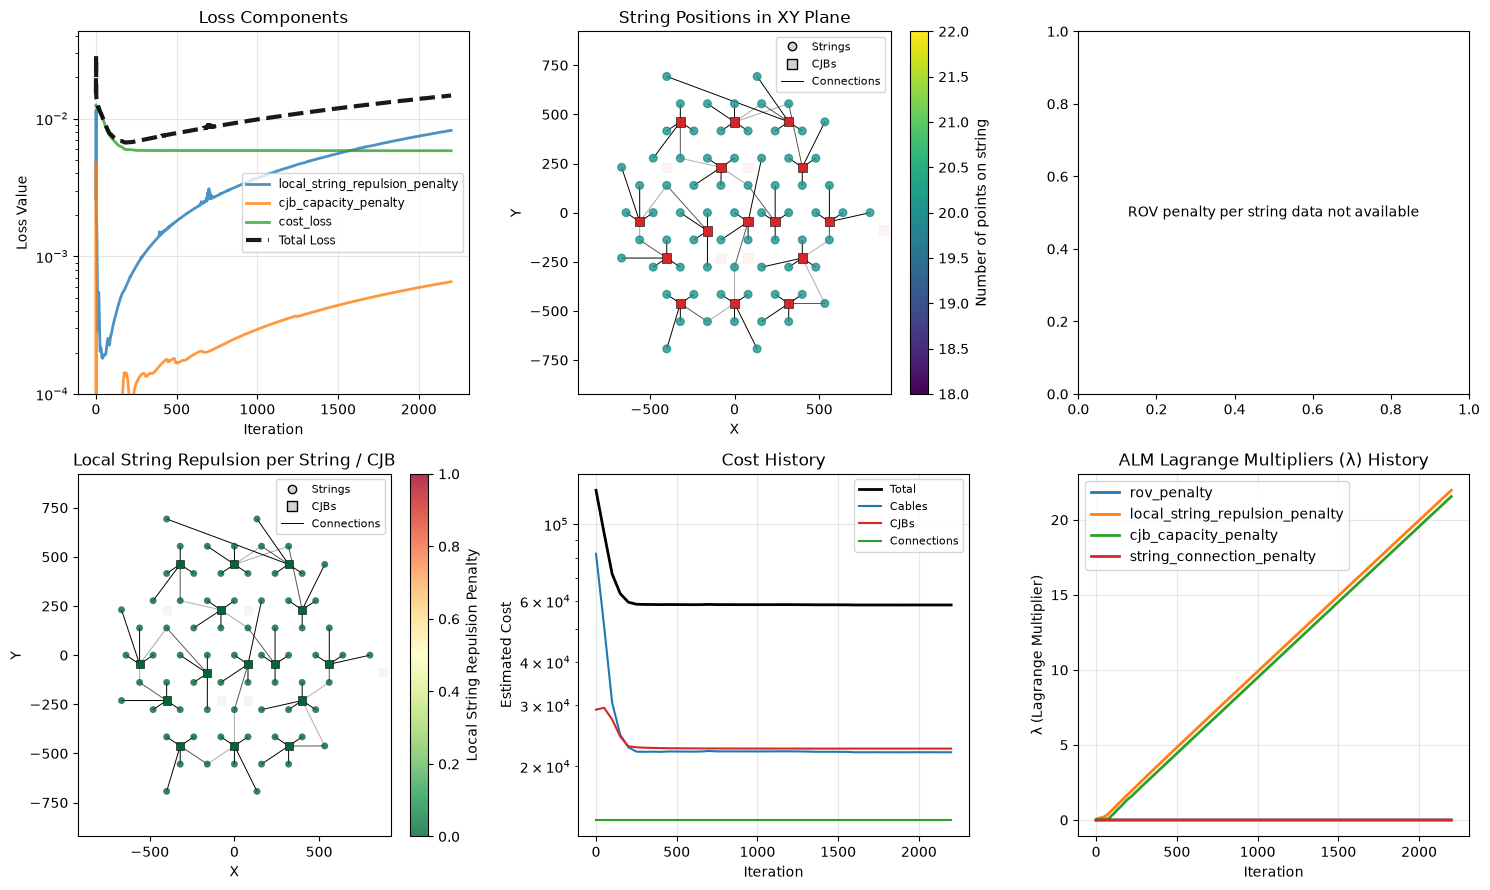

Saved GIF frame 45 to /tmp/gif_frames_d7wjtg95/frame_49544.png
Iter 2201/20000, Total Loss: 0.0147 | local_string_repulsion_penalty: 0.0082 | cjb_capacity_penalty: 0.0007 | cost_loss: 0.0058
Saved GIF frame 46 to /tmp/gif_frames_d7wjtg95/frame_51795.png
Iter 2251/20000, Total Loss: 0.0149 | local_string_repulsion_penalty: 0.0084 | cjb_capacity_penalty: 0.0007 | cost_loss: 0.0058


In [ ]:
# Begin optimization process, combining all the configurations

# optimizer.visualizer.cleanup_gif_temp_files()
geom_dict = optimizer.optimize(
    # clear_cuda_cache=True,                 # Clear torch GPU memory cache between iterations
    loss_func_dict=loss_func_dict,          # Dictionary of loss functions to use
    loss_weights_dict=loss_weights_dict,    # Weights for combining multiple losses
    loss_params_dict=loss_params,           # Parameters for loss function computation
    n_iter=20000,                           # Maximum number of optimization iterations
    vis_kwargs=vis_kwargs,                 # Visualization parameters
    print_freq=50,                          # Print progress every N iterations
    vis_freq=100,                           # Create plots every N iterations
    gif_freq=50,                           # Save animation frames every N iterations
    sigmoid_loss_list=loss_sigmoid_list,         # Which losses to apply sigmoid to (for better optimization dynamics)
    revert_on_nan=True,                      # Revert geometry if loss becomes NaN
    max_nan_retries=10,                          # Maximum number of consecutive NaN reverts before stopping
    # save_geom_folder='./cjb_hex_test_no_rov',  # Directory to save geometry checkpoints
    # save_geom_freq=100,                      # Save geometry every N iterations
    # continue_saving=False,
    # save_best_geom_file = './best_geom_1_event.pkl',  # File to save best geometry found
    # save_last_geom = False, 
    # loss_dict=loss_dict,         # resupply loss histories if continuing optimization (only for visualization)
    # uw_loss_dict=uw_loss_dict,   
    # vis_loss_dict=vis_loss_dict, 
    # vis_uw_loss_dict=vis_uw_loss_dict 
)

In [ ]:
# optimizer.visualizer.finalize_gif(
#     gif_filename='../gifs/opt_test_cjb_hex.gif',  # Output filename
#     gif_fps=10,                    # Animation frame rate
#     cleanup_images=False           # Keep individual frames for debugging
# )